# Тема 1. Моделирование геометрической вероятности
---
Смоделируйте вычисление геометрической вероятности (на примере из лекции про метание дротиков в игровой круг, площадь которого в два раза меньше площади стены). Показать теоретический расчет и графическую иллюстрацию для рассматриваемого примера.
---

---
## Задача:

> Представьте себе баскетбольный щит, на котором нарисован квадрат для броска размером 1.5 × 1.5 метра (зона, куда обычно целится игрок). В центре этого квадрата расположено кольцо в форме круга диаметром 45 см. Игрок бросает мяч случайным образом — мяч попадает равномерно в любую точку квадрата (идеальный бросок «наугад»).
Какова вероятность, что мяч попадёт в кольцо?

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

### Параметры:

In [7]:
np.random.seed(42)
N = 100000

square_side = 1.5              # м
ring_diameter = 0.45           # м
ring_radius = ring_diameter / 2

S_square = square_side ** 2
S_ring = np.pi * ring_radius ** 2
P_theory = S_ring / S_square

print("ЗАДАЧА «Мяч и баскетбольное кольцо»\n")
print(f"Сторона квадрата:      a = {square_side} м")
print(f"Диаметр кольца:        d = {ring_diameter} м = 45 см")
print(f"S квадрата:            {S_square:.4f} м² = {S_square*10000:.0f} см²")
print(f"S кольца:              {S_ring:.4f} м² = {S_ring*10000:.2f} см²")
print(f"Теоретическая P:       {P_theory:.6f} = {P_theory*100:.4f}%")

ЗАДАЧА «Мяч и баскетбольное кольцо»

Сторона квадрата:      a = 1.5 м
Диаметр кольца:        d = 0.45 м = 45 см
S квадрата:            2.2500 м² = 22500 см²
S кольца:              0.1590 м² = 1590.43 см²
Теоретическая P:       0.070686 = 7.0686%


### Симуляция:

In [8]:
half = square_side / 2

x = np.random.uniform(-half, half, N)
y = np.random.uniform(-half, half, N)

in_ring = x**2 + y**2 <= ring_radius**2
P_model = in_ring.mean()

print(f"\nСмоделированная P:     {P_model:.6f} = {P_model*100:.4f}%")
print(f"Абсолютная погрешность: {abs(P_model - P_theory):.6f}")
print(f"Попаданий в кольцо:     {in_ring.sum()} из {N}")



Смоделированная P:     0.071840 = 7.1840%
Абсолютная погрешность: 0.001154
Попаданий в кольцо:     7184 из 100000


### Визуализация:

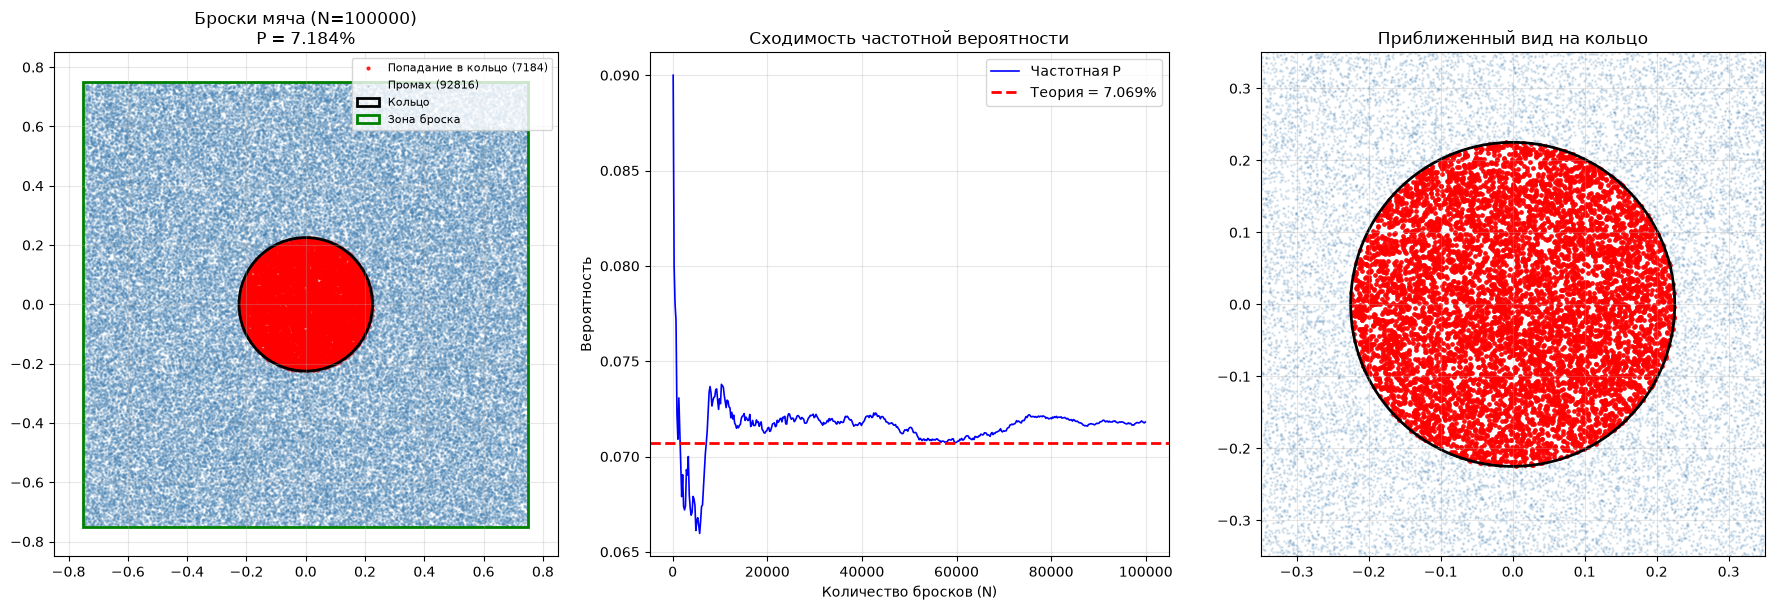

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- График 1: все точки ---
axes[0].scatter(x[in_ring], y[in_ring], c='red', s=4, alpha=0.8,
                label=f'Попадание в кольцо ({in_ring.sum()})')
axes[0].scatter(x[~in_ring], y[~in_ring], c='steelblue', s=1, alpha=0.2,
                label=f'Промах ({(~in_ring).sum()})')
axes[0].add_patch(Circle((0, 0), ring_radius, fill=False,
                         color='black', linewidth=2, label='Кольцо'))
axes[0].add_patch(Rectangle((-half, -half), square_side, square_side,
                             fill=False, color='green', linewidth=2,
                             label='Зона броска'))
axes[0].set_xlim(-0.85, 0.85); axes[0].set_ylim(-0.85, 0.85)
axes[0].set_aspect('equal')
axes[0].set_title(f'Броски мяча (N={N})\nP = {P_model*100:.3f}%')
axes[0].legend(loc='upper right', fontsize=8)
axes[0].grid(True, alpha=0.3)

# --- График 2: сходимость ---
N_range = np.arange(100, N+1, 200)
conv = [in_ring[:n].mean() for n in N_range]
axes[1].plot(N_range, conv, 'b-', linewidth=1.2, label='Частотная P')
axes[1].axhline(P_theory, color='red', linestyle='--', linewidth=2,
                label=f'Теория = {P_theory*100:.3f}%')
axes[1].set_xlabel('Количество бросков (N)')
axes[1].set_ylabel('Вероятность')
axes[1].set_title('Сходимость частотной вероятности')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# --- График 3: увеличенный вид на кольцо ---
axes[2].scatter(x[in_ring], y[in_ring], c='red', s=6, alpha=0.9)
axes[2].scatter(x[~in_ring], y[~in_ring], c='steelblue', s=1, alpha=0.15)
axes[2].add_patch(Circle((0, 0), ring_radius, fill=False,
                         color='black', linewidth=2))
axes[2].set_xlim(-0.35, 0.35); axes[2].set_ylim(-0.35, 0.35)
axes[2].set_aspect('equal')
axes[2].set_title('Приближенный вид на кольцо')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()